In [1]:
from google.colab import files

uploaded = files.upload()


Saving Mall_Customers.csv to Mall_Customers.csv


In [2]:
import pandas as pd

df = pd.read_csv("Mall_Customers.csv")

df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler

from sklearn.cluster import KMeans
from sklearn.cluster import AgglomerativeClustering
from sklearn.cluster import DBSCAN

from sklearn.metrics import silhouette_score
from sklearn.metrics import davies_bouldin_score

from scipy.cluster.hierarchy import dendrogram, linkage

import warnings
warnings.filterwarnings("ignore")

In [4]:
df = pd.read_csv("Mall_Customers.csv")

df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [5]:
df.shape

(200, 5)

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB


In [7]:
df.describe()

,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


In [8]:
df.isnull().sum()

,0
CustomerID,0
Gender,0
Age,0
Annual Income (k$),0
Spending Score (1-100),0


In [9]:
df.duplicated().sum()

np.int64(0)

In [10]:
df = df.drop_duplicates()

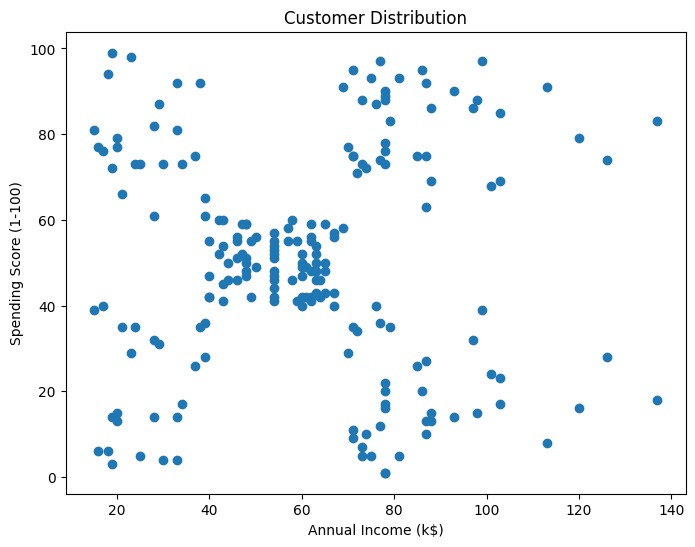

In [11]:
plt.figure(figsize=(8, 6))

plt.scatter(
    df["Annual Income (k$)"],
    df["Spending Score (1-100)"]
)

plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.title("Customer Distribution")

plt.show()

In [12]:
X = df[["Annual Income (k$)", "Spending Score (1-100)"]]

In [13]:
X.head()

,Annual Income (k$),Spending Score (1-100)
0,15,39
1,15,81
2,16,6
3,16,77
4,17,40


In [14]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

In [15]:
X_scaled_df = pd.DataFrame(
    X_scaled,
    columns=["Annual Income", "Spending Score"]
)

X_scaled_df.head()

,Annual Income,Spending Score
0,-1.738999,-0.434801
1,-1.738999,1.195704
2,-1.700830,-1.715913
3,-1.700830,1.040418
4,-1.662660,-0.395980


Algorithm 1 — K-Means

Step 1: Find the optimal K


In [16]:
inertia = []

for k in range(2, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)

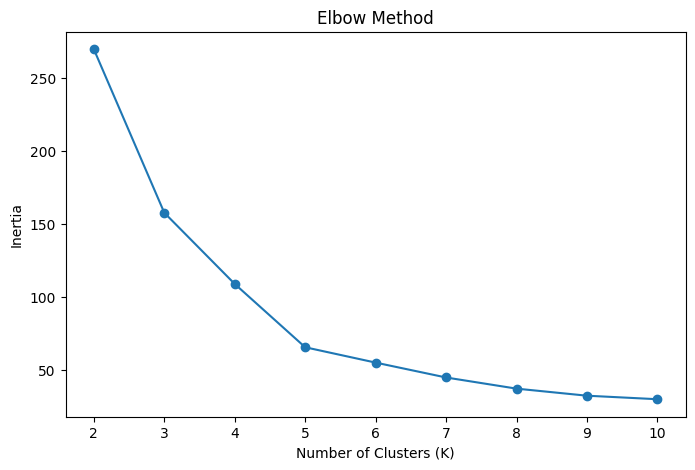

In [17]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(2, 11),
    inertia,
    marker="o"
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method")

plt.show()

Train K-Means

In [18]:
kmeans = KMeans(
    n_clusters=5,
    random_state=42,
    n_init=10
)

kmeans_labels = kmeans.fit_predict(X_scaled)

In [19]:
df["KMeans_Cluster"] = kmeans_labels

In [21]:
df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),KMeans_Cluster
0,1,Male,19,15,39,4
1,2,Male,21,15,81,2
2,3,Female,20,16,6,4
3,4,Female,23,16,77,2
4,5,Female,31,17,40,4


Visualize K-Means

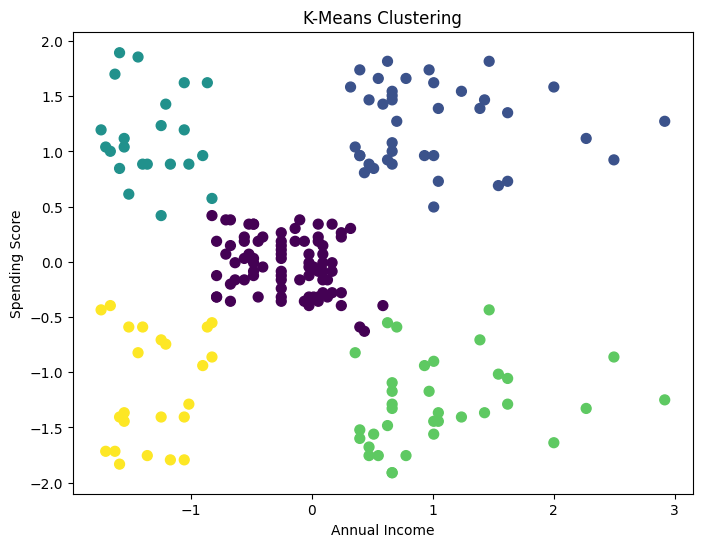

In [22]:
plt.figure(figsize=(8, 6))

plt.scatter(
    X_scaled[:, 0],
    X_scaled[:, 1],
    c=kmeans_labels,
    s=50
)

plt.xlabel("Annual Income")
plt.ylabel("Spending Score")
plt.title("K-Means Clustering")

plt.show()

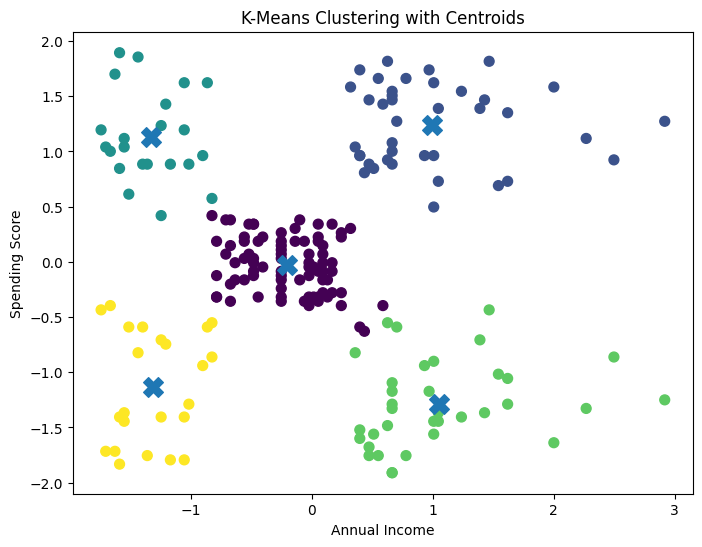

In [23]:
centers = kmeans.cluster_centers_

plt.figure(figsize=(8, 6))

plt.scatter(
    X_scaled[:, 0],
    X_scaled[:, 1],
    c=kmeans_labels,
    s=50
)

plt.scatter(
    centers[:, 0],
    centers[:, 1],
    marker="X",
    s=200
)

plt.xlabel("Annual Income")
plt.ylabel("Spending Score")
plt.title("K-Means Clustering with Centroids")

plt.show()

Evaluate K-Means
Silhouette Score

In [24]:
kmeans_silhouette = silhouette_score(
    X_scaled,
    kmeans_labels
)

print("K-Means Silhouette Score:",
      kmeans_silhouette)

K-Means Silhouette Score: 0.5546571631111091


Davies-Bouldin Index

In [25]:
kmeans_db = davies_bouldin_score(
    X_scaled,
    kmeans_labels
)

print("K-Means Davies-Bouldin Index:",
      kmeans_db)

K-Means Davies-Bouldin Index: 0.5722356162263352


Algorithm 2 — Agglomerative Hierarchical Clustering

visualize dendogram

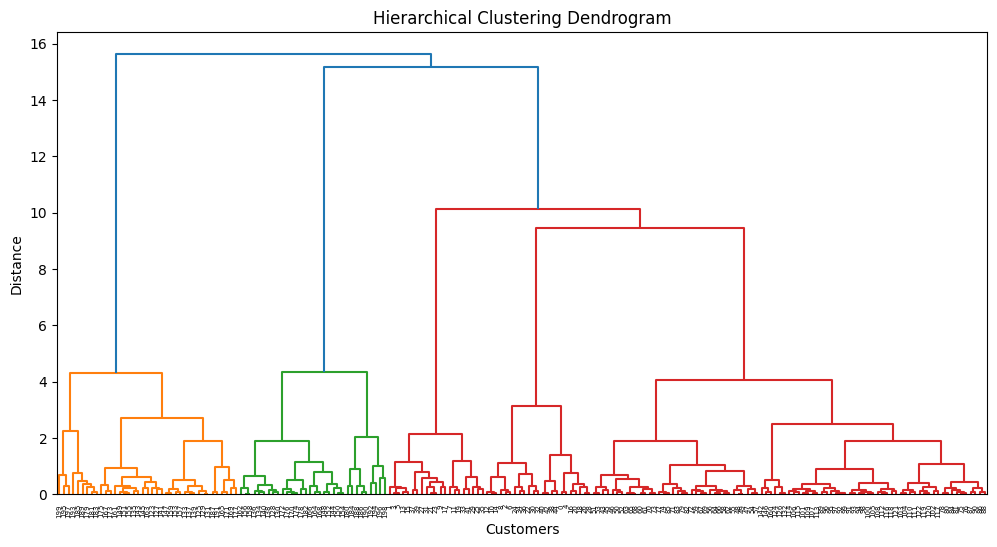

In [26]:
plt.figure(figsize=(12, 6))

linkage_matrix = linkage(
    X_scaled,
    method="ward"
)

dendrogram(linkage_matrix)

plt.title("Hierarchical Clustering Dendrogram")
plt.xlabel("Customers")
plt.ylabel("Distance")

plt.show()

Apply Agglomerative Clustering

In [27]:
hierarchical = AgglomerativeClustering(
    n_clusters=5,
    linkage="ward"
)

hierarchical_labels = hierarchical.fit_predict(X_scaled)

In [28]:
df["Hierarchical_Cluster"] = hierarchical_labels

Visualize Hierarchical Clustering

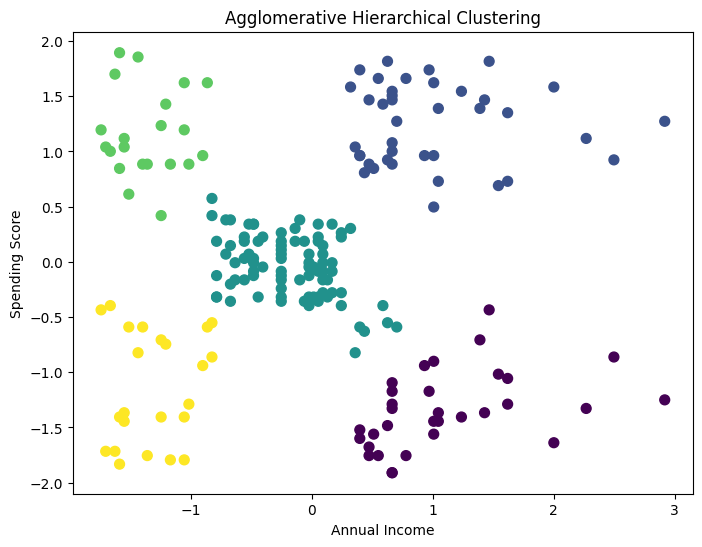

In [29]:
plt.figure(figsize=(8, 6))

plt.scatter(
    X_scaled[:, 0],
    X_scaled[:, 1],
    c=hierarchical_labels,
    s=50
)

plt.xlabel("Annual Income")
plt.ylabel("Spending Score")
plt.title("Agglomerative Hierarchical Clustering")

plt.show()

Evaluate Hierarchical Clustering

In [30]:
hierarchical_silhouette = silhouette_score(
    X_scaled,
    hierarchical_labels
)

hierarchical_db = davies_bouldin_score(
    X_scaled,
    hierarchical_labels
)

print(
    "Agglomerative Silhouette Score:",
    hierarchical_silhouette
)

print(
    "Agglomerative Davies-Bouldin Index:",
    hierarchical_db
)

Agglomerative Silhouette Score: 0.5538089226688662
Agglomerative Davies-Bouldin Index: 0.5778621190740154


Algorithm 3 — DBSCAN

In [31]:
dbscan = DBSCAN(
    eps=0.3,
    min_samples=5
)

dbscan_labels = dbscan.fit_predict(X_scaled)

In [32]:
np.unique(dbscan_labels)

array([-1,  0,  1,  2,  3,  4,  5,  6])

Visualize DBSCAN

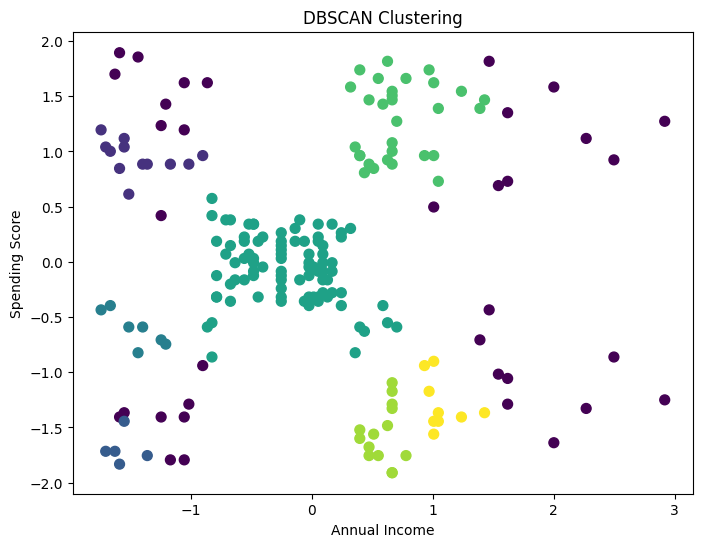

In [33]:
plt.figure(figsize=(8, 6))

plt.scatter(
    X_scaled[:, 0],
    X_scaled[:, 1],
    c=dbscan_labels,
    s=50
)

plt.xlabel("Annual Income")
plt.ylabel("Spending Score")
plt.title("DBSCAN Clustering")

plt.show()

Tuning DBSCAN

In [34]:
eps_values = [0.2, 0.25, 0.3, 0.35, 0.4, 0.45, 0.5]

for eps in eps_values:

    model = DBSCAN(
        eps=eps,
        min_samples=5
    )

    labels = model.fit_predict(X_scaled)

    n_clusters = len(
        set(labels) - {-1}
    )

    n_noise = list(labels).count(-1)

    print(
        f"eps={eps}: "
        f"clusters={n_clusters}, "
        f"noise={n_noise}"
    )

eps=0.2: clusters=7, noise=77
eps=0.25: clusters=6, noise=50
eps=0.3: clusters=7, noise=35
eps=0.35: clusters=6, noise=23
eps=0.4: clusters=4, noise=15
eps=0.45: clusters=3, noise=11
eps=0.5: clusters=2, noise=8


Algorithm 4 — Divisive Clustering

In [35]:
def divisive_clustering(X, n_clusters=5):

    clusters = [np.arange(len(X))]

    while len(clusters) < n_clusters:

        # Find the largest cluster
        largest_index = np.argmax(
            [len(cluster) for cluster in clusters]
        )

        cluster_to_split = clusters.pop(largest_index)

        # Split using K-Means
        kmeans = KMeans(
            n_clusters=2,
            random_state=42,
            n_init=10
        )

        labels = kmeans.fit_predict(
            X[cluster_to_split]
        )

        cluster_1 = cluster_to_split[labels == 0]
        cluster_2 = cluster_to_split[labels == 1]

        clusters.append(cluster_1)
        clusters.append(cluster_2)

    final_labels = np.zeros(len(X), dtype=int)

    for cluster_id, cluster in enumerate(clusters):
        final_labels[cluster] = cluster_id

    return final_labels

In [36]:
divisive_labels = divisive_clustering(
    X_scaled,
    n_clusters=5
)

Visualize Divisive Clustering

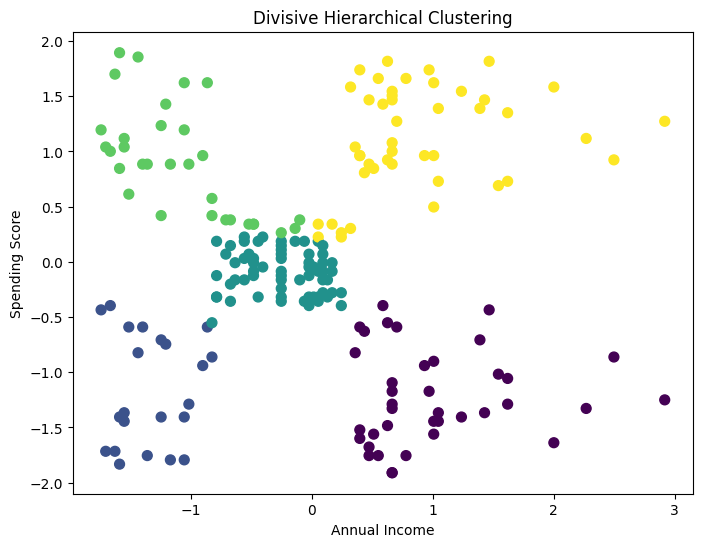

In [37]:
plt.figure(figsize=(8, 6))

plt.scatter(
    X_scaled[:, 0],
    X_scaled[:, 1],
    c=divisive_labels,
    s=50
)

plt.xlabel("Annual Income")
plt.ylabel("Spending Score")
plt.title("Divisive Hierarchical Clustering")

plt.show()

Evaluate Divisive Clustering

In [38]:
divisive_silhouette = silhouette_score(
    X_scaled,
    divisive_labels
)

divisive_db = davies_bouldin_score(
    X_scaled,
    divisive_labels
)

print(
    "Divisive Silhouette Score:",
    divisive_silhouette
)

print(
    "Divisive Davies-Bouldin Index:",
    divisive_db
)

Divisive Silhouette Score: 0.4613388786030268
Divisive Davies-Bouldin Index: 0.6592517227641472


In [40]:
# DBSCAN evaluation

unique_labels = set(dbscan_labels)
n_clusters = len(unique_labels - {-1})

print("DBSCAN clusters found:", n_clusters)
print("DBSCAN labels:", unique_labels)

if n_clusters >= 2:
    # Remove noise points (-1) for evaluation
    mask = dbscan_labels != -1

    dbscan_silhouette = silhouette_score(
        X_scaled[mask],
        dbscan_labels[mask]
    )

    dbscan_db = davies_bouldin_score(
        X_scaled[mask],
        dbscan_labels[mask]
    )

    print("DBSCAN Silhouette Score:", dbscan_silhouette)
    print("DBSCAN Davies-Bouldin Index:", dbscan_db)

else:
    dbscan_silhouette = np.nan
    dbscan_db = np.nan

    print("DBSCAN did not produce enough clusters for evaluation.")

DBSCAN clusters found: 7
DBSCAN labels: {np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(-1)}
DBSCAN Silhouette Score: 0.5243276105881419
DBSCAN Davies-Bouldin Index: 0.5799545599064792


In [41]:
results = pd.DataFrame({
    "Algorithm": [
        "K-Means",
        "Agglomerative",
        "DBSCAN",
        "Divisive"
    ],
    "Silhouette Score": [
        kmeans_silhouette,
        hierarchical_silhouette,
        dbscan_silhouette,
        divisive_silhouette
    ],
    "Davies-Bouldin Index": [
        kmeans_db,
        hierarchical_db,
        dbscan_db,
        divisive_db
    ]
})

results

,Algorithm,Silhouette Score,Davies-Bouldin Index
0,K-Means,0.554657,0.572236
1,Agglomerative,0.553809,0.577862
2,DBSCAN,0.524328,0.579955
3,Divisive,0.461339,0.659252


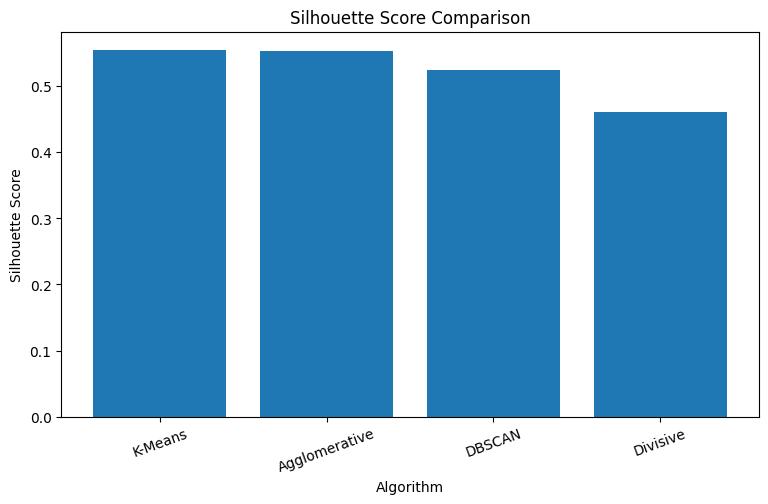

In [42]:
plt.figure(figsize=(9, 5))

plt.bar(
    results["Algorithm"],
    results["Silhouette Score"]
)

plt.xlabel("Algorithm")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score Comparison")

plt.xticks(rotation=20)

plt.show()

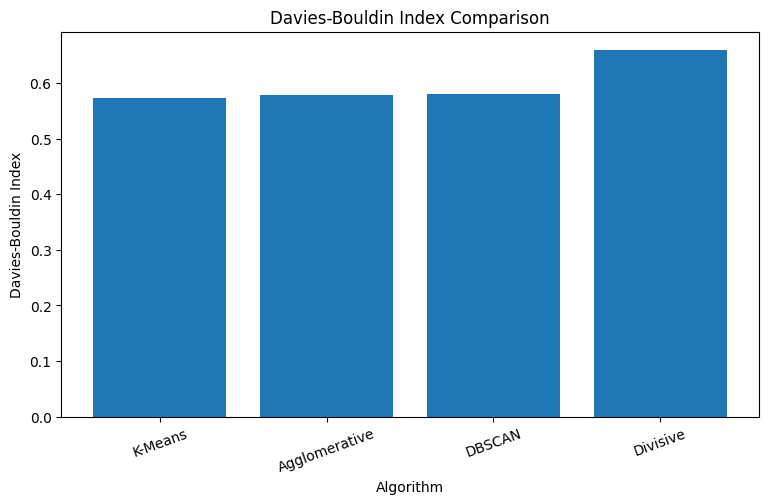

In [43]:
plt.figure(figsize=(9, 5))

plt.bar(
    results["Algorithm"],
    results["Davies-Bouldin Index"]
)

plt.xlabel("Algorithm")
plt.ylabel("Davies-Bouldin Index")
plt.title("Davies-Bouldin Index Comparison")

plt.xticks(rotation=20)

plt.show()

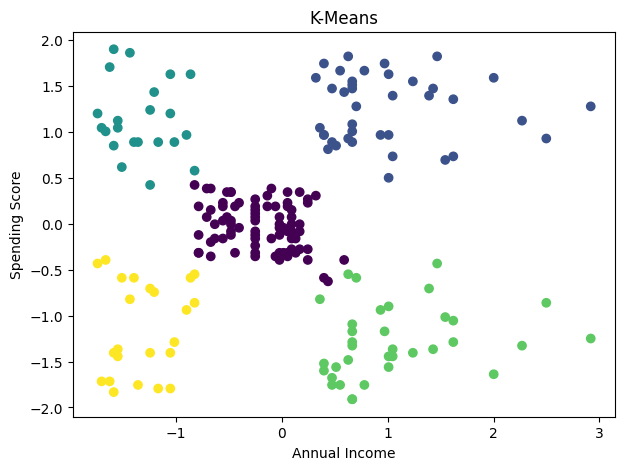

In [44]:
plt.figure(figsize=(7, 5))

plt.scatter(
    X_scaled[:, 0],
    X_scaled[:, 1],
    c=kmeans_labels
)

plt.title("K-Means")
plt.xlabel("Annual Income")
plt.ylabel("Spending Score")

plt.show()

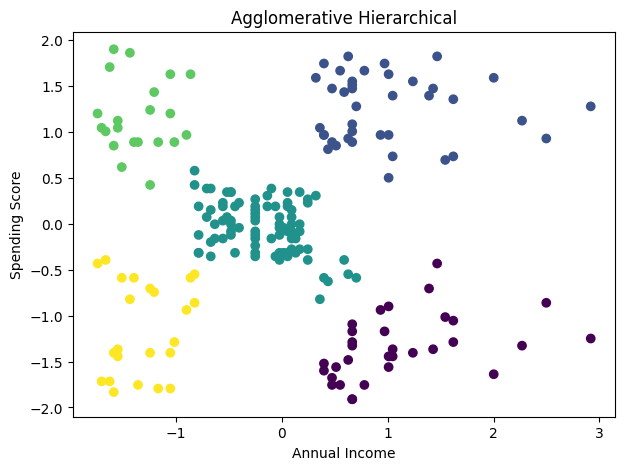

In [45]:
plt.figure(figsize=(7, 5))

plt.scatter(
    X_scaled[:, 0],
    X_scaled[:, 1],
    c=hierarchical_labels
)

plt.title("Agglomerative Hierarchical")
plt.xlabel("Annual Income")
plt.ylabel("Spending Score")

plt.show()

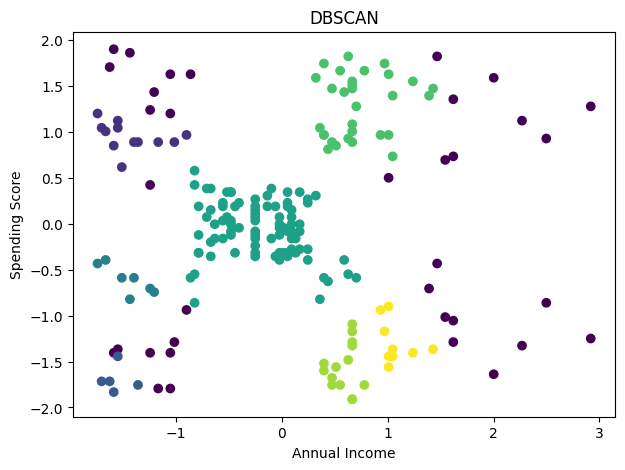

In [46]:
plt.figure(figsize=(7, 5))

plt.scatter(
    X_scaled[:, 0],
    X_scaled[:, 1],
    c=dbscan_labels
)

plt.title("DBSCAN")
plt.xlabel("Annual Income")
plt.ylabel("Spending Score")

plt.show()

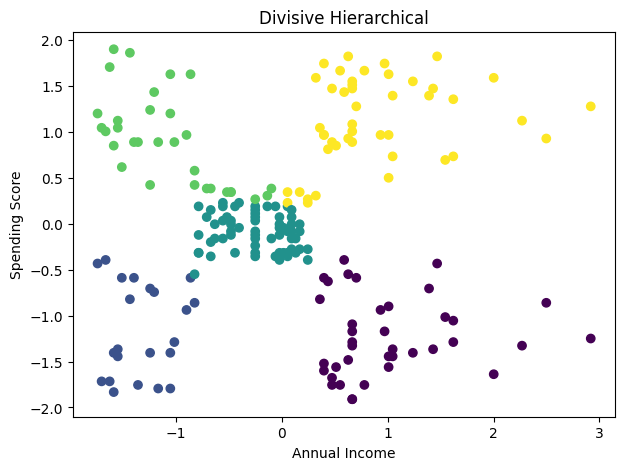

In [47]:
plt.figure(figsize=(7, 5))

plt.scatter(
    X_scaled[:, 0],
    X_scaled[:, 1],
    c=divisive_labels
)

plt.title("Divisive Hierarchical")
plt.xlabel("Annual Income")
plt.ylabel("Spending Score")

plt.show()

In [48]:
df["KMeans_Cluster"] = kmeans_labels

In [49]:
cluster_summary = df.groupby(
    "KMeans_Cluster"
)[
    ["Age", "Annual Income (k$)", "Spending Score (1-100)"]
].mean()

cluster_summary

,Age,Annual Income (k$),Spending Score (1-100)
KMeans_Cluster,,,
0,42.716049,55.296296,49.518519
1,32.692308,86.538462,82.128205
2,25.272727,25.727273,79.363636
3,41.114286,88.200000,17.114286
4,45.217391,26.304348,20.913043
